---

## Setup

The California Housing dataset: 20,640 block groups, 8 features and the median house value. we are not using labels, so the house value is kept as a ninth feature.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from scipy import stats

plt.style.use('dark_background')
np.random.seed(42)

california = fetch_california_housing()
X = np.column_stack([california.data, california.target])


In [20]:
X

array([[   8.3252    ,   41.        ,    6.98412698, ...,   37.88      ,
        -122.23      ,    4.526     ],
       [   8.3014    ,   21.        ,    6.23813708, ...,   37.86      ,
        -122.22      ,    3.585     ],
       [   7.2574    ,   52.        ,    8.28813559, ...,   37.85      ,
        -122.24      ,    3.521     ],
       ...,
       [   1.7       ,   17.        ,    5.20554273, ...,   39.43      ,
        -121.22      ,    0.923     ],
       [   1.8672    ,   18.        ,    5.32951289, ...,   39.43      ,
        -121.32      ,    0.847     ],
       [   2.3886    ,   16.        ,    5.25471698, ...,   39.37      ,
        -121.24      ,    0.894     ]], shape=(20640, 9))

In [21]:
X[0]

array([   8.3252    ,   41.        ,    6.98412698,    1.02380952,
        322.        ,    2.55555556,   37.88      , -122.23      ,
          4.526     ])

In [22]:
feature_names = list(california.feature_names) + ['MedHouseVal']
feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude',
 'MedHouseVal']

In [23]:
# ndim : number of dimensions
print(f"X: ndim = {X.ndim}, shape = {X.shape}  (samples, features)\n")
for i, name in enumerate(feature_names):
    print(f"  {i}: {name:<12} min = {X[:, i].min():>9.2f}   max = {X[:, i].max():>10.2f}")

X: ndim = 2, shape = (20640, 9)  (samples, features)

  0: MedInc       min =      0.50   max =      15.00
  1: HouseAge     min =      1.00   max =      52.00
  2: AveRooms     min =      0.85   max =     141.91
  3: AveBedrms    min =      0.33   max =      34.07
  4: Population   min =      3.00   max =   35682.00
  5: AveOccup     min =      0.69   max =    1243.33
  6: Latitude     min =     32.54   max =      41.95
  7: Longitude    min =   -124.35   max =    -114.31
  8: MedHouseVal  min =      0.15   max =       5.00


A row is one sample (a feature vector, one point in a 9-dimensional space). A column is one feature measured on all samples.

In [24]:
scalar = X[0, 0]      # 0D: one value
sample = X[0, :]      # 1D: one sample, all features
feature = X[:, 0]     # 1D: one feature, all samples

for name, obj in [('scalar', scalar), ('sample', sample), ('feature', feature), ('dataset', X)]:
    print(f"{name:<8} ndim = {np.ndim(obj)}, shape = {np.shape(obj)}")

scalar   ndim = 0, shape = ()
sample   ndim = 1, shape = (9,)
feature  ndim = 1, shape = (20640,)
dataset  ndim = 2, shape = (20640, 9)


---

## Part 3: Descriptive Statistics

### Example 3a: Mean, trimmed mean and median under outliers

Fifteen heights in cm, then the same data with three entry errors.

160,170,180  mean=170

160,170,600 mean=310

160,170,180,190,200 median=180

160,170,180,190 median=175

160,170,180,190,600 median=180

10,12,13,14,15,16,17,18,100  p=1 trimmedmean= 15

In [25]:
def trimmed_mean(x, p):
    """Mean after removing the p smallest and the p largest values."""
    x_sorted = np.sort(x)
    return np.mean(x_sorted[p:len(x) - p])

heights = np.array([165, 178, 182, 159, 174, 188, 171, 163, 179, 176, 184, 169, 167, 173, 181])

heights_bad = heights.copy()
heights_bad[[3, 10, 5]] = [26, 521, 680]

print(f"{'Estimate':<16} {'Clean':<12} {'With outliers':<14}")
print("=" * 42)
print(f"{'Mean':<16} {np.mean(heights):<12.2f} {np.mean(heights_bad):<14.2f}")
print(f"{'Trimmed (p=3)':<16} {trimmed_mean(heights, 3):<12.2f} {trimmed_mean(heights_bad, 3):<14.2f}")
print(f"{'Median':<16} {np.median(heights):<12.2f} {np.median(heights_bad):<14.2f}")

Estimate         Clean        With outliers 
Mean             173.93       220.33        
Trimmed (p=3)    174.22       174.22        
Median           174.00       174.00        


Real data already contains outliers. AveOccup is the average number of people per household.

Mean:              3.071
Trimmed mean (5%): 2.878   (scipy: 2.878)
Median:            2.818
Five largest:      [  83.2  230.2  502.5  599.7 1243.3]


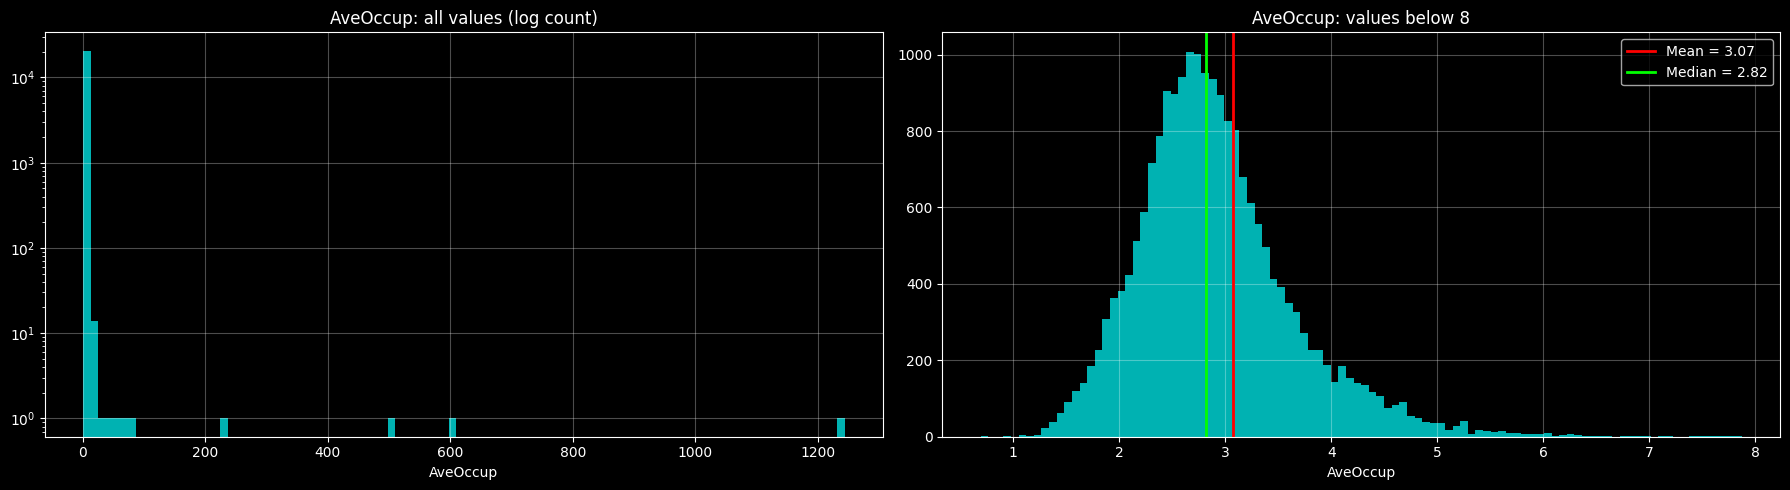

In [26]:
occup = X[:, 5]
p5 = int(0.05 * len(occup))          # 5% of the samples from each side # 1032

print(f"Mean:              {np.mean(occup):.3f}")
print(f"Trimmed mean (5%): {trimmed_mean(occup, p5):.3f}   (scipy: {stats.trim_mean(occup, 0.05):.3f})")
print(f"Median:            {np.median(occup):.3f}")
print(f"Five largest:      {np.round(np.sort(occup)[-5:], 1)}")

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].hist(occup, bins=100, color='cyan', alpha=0.7)
axes[0].set_yscale('log')
axes[0].set_title('AveOccup: all values (log count)')
axes[0].set_xlabel('AveOccup')
axes[0].grid(True, alpha=0.3)

axes[1].hist(occup[occup < 8], bins=100, color='cyan', alpha=0.7)
axes[1].axvline(np.mean(occup), color='red', linewidth=2, label=f'Mean = {np.mean(occup):.2f}')
axes[1].axvline(np.median(occup), color='lime', linewidth=2, label=f'Median = {np.median(occup):.2f}')
axes[1].set_title('AveOccup: values below 8')
axes[1].set_xlabel('AveOccup')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Example 3b: Weighted mean

`Σ wᵢ xᵢ / Σ wᵢ`. Blocks have different populations, so the mean over blocks and the mean over people differ.

A: 10 years 100
B: 20 200
c: 40 700

In [27]:
house_age = X[:, 1]
population = X[:, 4]

weighted_age = (population @ house_age) / np.sum(population)

print(f"Mean HouseAge over blocks:            {np.mean(house_age):.3f}")
print(f"Mean HouseAge weighted by population: {weighted_age:.3f}   (np.average: {np.average(house_age, weights=population):.3f})")

Mean HouseAge over blocks:            28.639
Mean HouseAge weighted by population: 25.678   (np.average: 25.678)


### Example 3c: Variance, standard deviation and `n − 1`

The 20,640 blocks are treated as the population. Many small samples (n = 15) are drawn, and the variance of each is computed twice: dividing by `n` and by `n − 1`.

One sample:  divide by n = 2.4630   divide by n - 1 = 2.6389
NumPy:       np.var(sample) = 2.4630   np.var(sample, ddof=1) = 2.6389

Population variance:          3.6091
Average variance using n:     3.4006
Average variance using n - 1: 3.6435


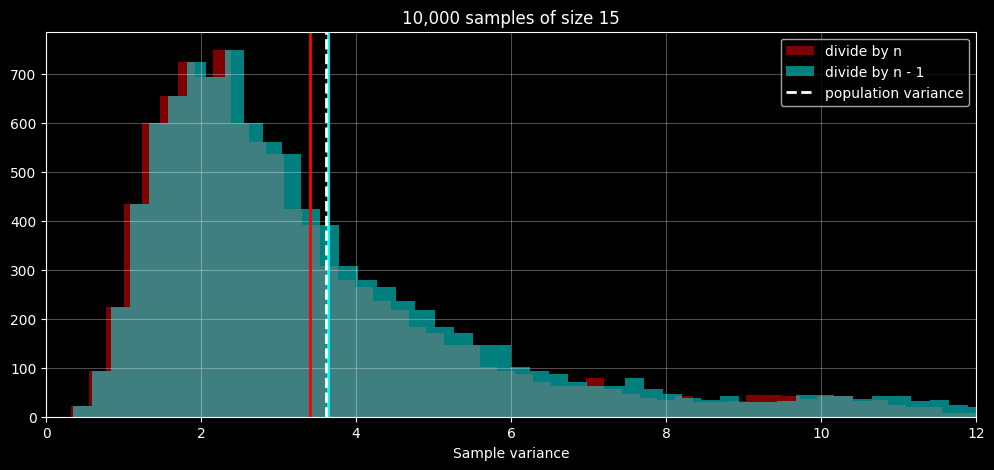

In [28]:
income = X[:, 0]
sigma2 = np.sum((income - np.mean(income))**2) / len(income)      # population variance: divide by N

# one sample, step by step
sample = np.random.choice(income, 15, replace=False)
n = len(sample)
squared_deviations = (sample - np.mean(sample))**2
print(f"One sample:  divide by n = {np.sum(squared_deviations) / n:.4f}   divide by n - 1 = {np.sum(squared_deviations) / (n - 1):.4f}")
print(f"NumPy:       np.var(sample) = {np.var(sample):.4f}   np.var(sample, ddof=1) = {np.var(sample, ddof=1):.4f}\n") # Delta Degrees of Freedom

# 10,000 samples, one per row
many_samples = np.random.choice(income, size=(10000, 15))
var_n = np.var(many_samples, axis=1, ddof=0)
var_n1 = np.var(many_samples, axis=1, ddof=1)

print(f"Population variance:          {sigma2:.4f}")
print(f"Average variance using n:     {np.mean(var_n):.4f}")
print(f"Average variance using n - 1: {np.mean(var_n1):.4f}")

plt.figure(figsize=(12, 5))
plt.hist(var_n, bins=80, alpha=0.5, color='red', label='divide by n')
plt.hist(var_n1, bins=80, alpha=0.5, color='cyan', label='divide by n - 1')
plt.axvline(np.mean(var_n), color='red', linewidth=2)
plt.axvline(np.mean(var_n1), color='cyan', linewidth=2)
plt.axvline(sigma2, color='white', linewidth=2, linestyle='--', label='population variance')
plt.xlim(0, 12)
plt.xlabel('Sample variance')
plt.title('10,000 samples of size 15')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Practice 3 (10 min)

Feature: AveRooms. `rooms_bad` is a copy in which 200 values were multiplied by 100.

1. On `rooms`, compute `rooms_mean`, `rooms_trimmed` (10% removed from each side) and `rooms_median`.
2. Compute the same three estimates on `rooms_bad`: `bad_mean`, `bad_trimmed`, `bad_median`.
3. `age_sample` holds 30 values of HouseAge. Compute its sample standard deviation `age_std` from scratch.

In [29]:
import random

rooms = X[:, 2]
rooms_bad = rooms.copy()

r = [random.randint(0, len(rooms_bad)) for _ in range(200)]
rooms_bad[r] = rooms_bad[r] * 100

# rooms stats
rooms_mean = np.mean(rooms)
rooms_trimmed = trimmed_mean(rooms, int((len(rooms) * 0.1)))
rooms_median = np.median(rooms)

# rooms bad stats
bad_mean = np.mean(rooms_bad)
bad_trimmed = trimmed_mean(rooms_bad, int((len(rooms_bad) * 0.1)))
bad_median = np.median(rooms_bad)

# age sample
age_sample = X[:, 1]

age_std = np.std(age_sample, ddof= 1)

# prints
print(f'rooms_mean=    {rooms_mean:.4f}')
print(f'rooms_trimmed= {rooms_trimmed:.4f}')
print(f'rooms_median=  {rooms_median:.4f}\n')

print(f'bad_mean=    {bad_mean:.4f}')
print(f'bad_trimmed= {bad_trimmed:.4f}')
print(f'bad_median=  {bad_median:.4f}\n')

print(f'age_std= {age_std:.4f}')

rooms_mean=    5.4290
rooms_trimmed= 5.2526
rooms_median=  5.2291

bad_mean=    10.4977
bad_trimmed= 5.2737
bad_median=  5.2443

age_std= 12.5856


---

## Part 4: Covariance and Correlation

### Example 4a: Why the covariance has a sign

`cov(x, y) = Σ (xᵢ − x̄)(yᵢ − ȳ) / (n − 1)`. After centering, each sample contributes the product of its two coordinates: positive in two quadrants, negative in the other two. the net sum of these contributions determines the final sign .. observe the mean and the sign of each sample with respect to that.

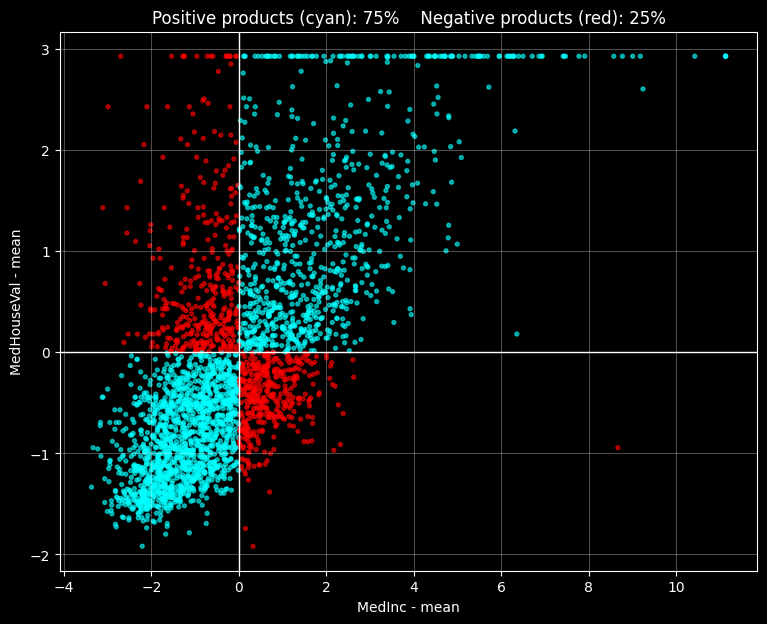

In [30]:
x = X[:, 0]    # MedIncf
y = X[:, 8]    # MedHouseVal
x_c = x - np.mean(x)
y_c = y - np.mean(y)

idx = np.random.choice(len(x), 3000, replace=False)
products = x_c[idx] * y_c[idx]

plt.figure(figsize=(9, 7))
plt.scatter(x_c[idx], y_c[idx], c=np.where(products > 0, 'cyan', 'red'), s=8, alpha=0.6)
plt.axhline(0, color='white', linewidth=1)
plt.axvline(0, color='white', linewidth=1)
plt.xlabel('MedInc - mean')
plt.ylabel('MedHouseVal - mean')
plt.title(f'Positive products (cyan): {np.mean(products > 0):.0%}    Negative products (red): {np.mean(products < 0):.0%}')
plt.grid(True, alpha=0.3)
plt.show()

### Example 4b: Covariance, Pearson and Spearman

The covariance is a dot product of the centered vectors. Pearson removes the units and equals the cosine similarity of the centered vectors. Spearman is Pearson computed on ranks.

(Ranking: If your raw data is $x = [45.2, 12.1, 99.5]$, you sort it and assign integer ranks: $x_{ranks} = [2, 1, 3]$. You do this independently for $y$.)

In [31]:
n = len(x)

cov_xy = (x_c @ y_c) / (n - 1)
pearson = cov_xy / (np.std(x, ddof=1) * np.std(y, ddof=1))
cosine_centered = (x_c @ y_c) / (np.sqrt(x_c @ x_c) * np.sqrt(y_c @ y_c))
spearman = np.corrcoef(stats.rankdata(x), stats.rankdata(y))[0, 1]

print(f"Covariance:                 {cov_xy:.4f}   (np.cov: {np.cov(x, y)[0, 1]:.4f})")
print(f"Pearson:                    {pearson:.4f}   (np.corrcoef: {np.corrcoef(x, y)[0, 1]:.4f})")
print(f"Cosine of centered vectors: {cosine_centered:.4f}")
print(f"Spearman:                   {spearman:.4f}   (scipy: {stats.spearmanr(x, y)[0]:.4f})")

Covariance:                 1.5085   (np.cov: 1.5085)
Pearson:                    0.6881   (np.corrcoef: 0.6881)
Cosine of centered vectors: 0.6881
Spearman:                   0.6768   (scipy: 0.6768)


All pairwise correlations with one matrix multiplication on the standardised data `Z`.

Equal to np.corrcoef: True


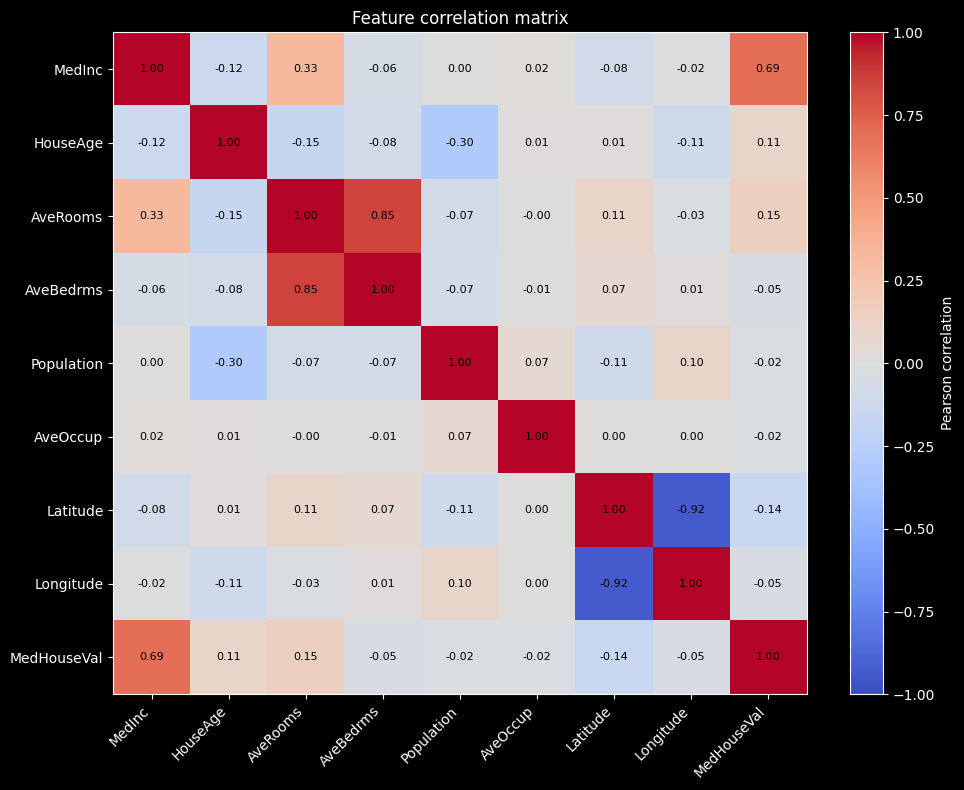

In [32]:
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)      # z-score: mean 0, std 1 per feature
correlation_matrix = (Z.T @ Z) / (len(Z) - 1)         # (9, 20640) @ (20640, 9) -> (9, 9)

print(f"Equal to np.corrcoef: {np.allclose(correlation_matrix, np.corrcoef(X.T))}")

plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(label='Pearson correlation')
plt.xticks(range(len(feature_names)), feature_names, rotation=45, ha='right')
plt.yticks(range(len(feature_names)), feature_names)
for i in range(len(feature_names)):
    for j in range(len(feature_names)):
        plt.text(j, i, f'{correlation_matrix[i, j]:.2f}', ha='center', va='center', fontsize=8, color='black')
plt.title('Feature correlation matrix')
plt.tight_layout()
plt.show()

### Practice 4 (8 min)

Features: AveRooms (2) and AveBedrms (3).

1. Compute `pearson_all` and `spearman_all` using all samples.
2. Build a boolean `mask` that keeps the samples whose AveRooms is below its 99th percentile (`np.percentile`).
3. Compute `pearson_masked` using only the samples in the mask.

In [33]:
ave_rooms = X[:, 2]
ave_bedrms = X[:, 3]

# pearson_all & spearman_all
pearson_all = np.corrcoef(ave_rooms, ave_bedrms)[0, 1]
spearman_all = stats.spearmanr(ave_rooms, ave_bedrms)[0]

# mask
threshold = np.percentile(ave_rooms, 99)
mask = ave_rooms < threshold

# pearson_maksed
masked_ave_rooms = ave_rooms[mask]
masked_ave_bedrms = ave_bedrms[mask]
pearson_masked = np.corrcoef(masked_ave_rooms, masked_ave_bedrms)[0, 1]

# Print
print(f'pearson_all:    {pearson_all:.4f}')
print(f'pearson_masked: {pearson_masked:.4f}')
print(f'spearman_all:   {spearman_all:.4f}')
print(f'spearman_all:   {spearman_all:.4f}')

pearson_all:    0.8476
pearson_masked: 0.2360
spearman_all:   0.0820
spearman_all:   0.0820


---

## Part 5: Similarity Search Without Labels

The nearest samples to a query, first on the raw features and then on the standardised features `Z` from Part 4.

In [34]:
query_index = 0

dist_raw = np.linalg.norm(X - X[query_index], axis=1)
dist_z = np.linalg.norm(Z - Z[query_index], axis=1)

nearest_raw = np.argsort(dist_raw)[1:4]      # position 0 is the query itself
nearest_z = np.argsort(dist_z)[1:4]

def show(indices, title):
    print(f"\n{title}")
    print(f"{'Sample':<8}" + "".join(f"{name:>12}" for name in feature_names))
    for i in [query_index] + list(indices):
        print(f"{i:<8}" + "".join(f"{value:>12.2f}" for value in X[i]))

show(nearest_raw, "Nearest samples on raw features (first row is the query):")
show(nearest_z, "Nearest samples on standardised features (first row is the query):")


Nearest samples on raw features (first row is the query):
Sample        MedInc    HouseAge    AveRooms   AveBedrms  Population    AveOccup    Latitude   Longitude MedHouseVal
0               8.33       41.00        6.98        1.02      322.00        2.56       37.88     -122.23        4.53
1529            5.66       38.00        6.15        1.01      319.00        2.59       37.89     -122.07        2.63
9005            6.40       42.00        5.48        1.07      324.00        2.47       34.12     -118.58        5.00
16572           2.83       38.00        5.77        1.10      320.00        2.39       37.74     -121.42        1.52

Nearest samples on standardised features (first row is the query):
Sample        MedInc    HouseAge    AveRooms   AveBedrms  Population    AveOccup    Latitude   Longitude MedHouseVal
0               8.33       41.00        6.98        1.02      322.00        2.56       37.88     -122.23        4.53
17159           8.28       37.00        6.75        1.

---

## Summary

- A sample is a vector and a dataset is a matrix; distance and cosine similarity are both built from the dot product.
- Rotation preserves distances between samples; scaling changes them, so feature scale determines which samples are similar.
- The mean follows outliers; the trimmed mean and the median are robust.
- The variance of a sample is divided by `n − 1`.
- Pearson correlation is the cosine similarity of centered features; Spearman uses ranks and is robust to outliers.